# Лабораторная работа №2 — POS-теггинг и синтаксический анализ (корпус Jeopardy)

Задание (tasks/lab2.md), 6 пунктов:

1. **POS-разметка** — готовый тэггер **stanza** (UD v4) к текстам корпуса.
2. **Распределение частей речи** — частоты по корпусу + сравнение по классам
   (раунды шоу), разбор ≥5 ошибок тэггера на шуме/сленге корпуса.
3. **Dependency parsing** — 10 предложений средней длины, визуализация деревьев.
4. **Извлечение паттернов** — обход синтаксического дерева: пары
   *[сущность + оценка]* (сущ./собств. + прилагательное) и
   *[субъект + действие]* (подлежащее + сказуемое).
5. **Топ-20 пар** по корпусу и их содержательный анализ.
6. **Разрешение анафоры** — rule-based: местоимения 3 л. → антецедент по
   морфологическому согласованию (род/число) и синтаксической дистанции, замена.

Корпус: `datasets/jeopardy.csv` (216 930 вопросов шоу Jeopardy!), целевая колонка
`Question` (как в lab1). Окружение: общее uv-окружение проекта, GPU (CUDA).


In [1]:
import html, re, os, sys, math, random, unicodedata
from collections import Counter, defaultdict

# режим CUDA-аллокатора: меньше фрагментации (важно для stanza BiLSTM на GPU)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import stanza
import torch

ROOT = "/home/miryz/projects/nlp"
DATA = os.path.join(ROOT, "datasets", "jeopardy.csv")
OUT  = os.path.join(ROOT, "lab2", "output")
os.makedirs(OUT, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# адаптивный выбор устройства: GPU только если реально свободно >= 6 GiB
# (stanza BiLSTM POS+depparse занимает несколько GiB VRAM)
if torch.cuda.is_available():
    free_b, total_b = torch.cuda.mem_get_info()
    DEVICE = "cuda" if free_b >= 6 * 1024**3 else "cpu"
    print(f"GPU свободно {free_b/1024**3:.2f} / {total_b/1024**3:.2f} GiB -> устройство: {DEVICE}")
else:
    DEVICE = "cpu"
    print("CUDA нет -> устройство: cpu")

GPU свободно 0.29 / 11.53 GiB -> устройство: cpu


## Пункт 0. Данные и лёгкая чистка

Колонки CSV ведут `Question` (как в lab1). Для теггинга нужна **естественная
проза**: шум lab1 (HTML, URL, деньги) не удаляем агрессивно, а нормализуем
минимально — HTML-сущности, теги, URL→`[URL]`, «умные» кавычки, схлоп пробелов.
Числа оставляем цифрами: тэггер их размечает сам (кардинальные числительные).

In [2]:
df = pd.read_csv(DATA)
df.columns = [c.strip() for c in df.columns]
df["Question"] = df["Question"].dropna()

TAG_RE   = re.compile(r"<[^>]+>")
ANCH_RE  = re.compile(r'<a\s+href="[^"]*">(.*?)</a>', re.I | re.S)
URL_RE   = re.compile(r"https?://\S+|www\.\S+")
MULTI_P  = re.compile(r"([!?])\1{2,}|\.{3}")
SMART    = {"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u00a0": " "}

def clean(text: str) -> str:
    t = html.unescape(text)
    t = ANCH_RE.sub(r"\1", t)          # текст ссылки оставляем
    t = URL_RE.sub(" [URL] ", t)
    t = TAG_RE.sub(" ", t)
    for k, v in SMART.items():
        t = t.replace(k, v)
    t = MULTI_P.sub(lambda m: " [ELLIPSIS] " if (m.group(0) and m.group(0)[0] == ".") else " [PUNCT] ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["text"] = df["Question"].map(clean)
print(len(df), "вопросов;", df["Round"].value_counts().to_dict())

# ЭДA: длины (в словах) — пригодятся для отбора «предложений средней длины»
df["n_words"] = df["text"].str.split().str.len()
print(df["n_words"].describe().round(2).to_string())

# Страта по Round (та же логика, что в lab1): фиксируем состав корпуса.
from sklearn.model_selection import train_test_split
sample10k, _ = train_test_split(df, train_size=10000, stratify=df["Round"],
                                random_state=SEED, shuffle=True)
sample10k = sample10k.reset_index(drop=True)
print("POS-выборка:", len(sample10k), sample10k["Round"].value_counts().to_dict())

216930 вопросов; {'Jeopardy!': 107384, 'Double Jeopardy!': 105912, 'Final Jeopardy!': 3631, 'Tiebreaker': 3}


count    216930.00
mean         14.52
std           5.86
min           0.00
25%          11.00
50%          15.00
75%          18.00
max         126.00


POS-выборка: 10000 {'Jeopardy!': 4950, 'Double Jeopardy!': 4882, 'Final Jeopardy!': 168}


## Пункт 1. POS-теггинг (stanza, UD v4)

Конвейер `tokenize → pos → lemma → depparse`. Для статистики частей речи —
10 000 стратифицированных вопросов (послезно, GPU). Пайплайн кэширует модели;
токенизация Jeopardy-вопросов ≈ один вопрос = одно предложение.

In [3]:
nlp_pos = stanza.Pipeline(lang="en",
                          processors="tokenize,pos,lemma",
                          use_gpu=(DEVICE == "cuda"),
                          verbose="ERROR")

# Stanza принимает пакетный текст как ОДНУ строку: каждая строка = документ
texts = sample10k["text"].tolist()
docs_pos = []
CHUNK = 2000
for i in range(0, len(texts), CHUNK):
    chunk = [t.replace("\n", " ") for t in texts[i:i+CHUNK]]
    docs_pos.append(nlp_pos("\n".join(chunk)))
    print(f"pos: обработано {min(i+CHUNK, len(texts))}/{len(texts)}")

# Плоский список токенов: (text, lemma, upos, xpos) по предложениям.
# s.words = UD-узлы (у Token леммы нет у multi-word токенов, у Word — есть у всех)
rows = []
for doc in docs_pos:
    for s in doc.sentences:
        rows.append([(w.text, w.lemma, w.upos, w.xpos) for w in s.words])
print("предложений:", len(rows),
      "; токенов:", sum(len(r) for r in rows))

2026-11-20 16:39:32 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2026-11-20 16:39:33 INFO: Downloaded file to /home/miryz/.cache/stanza/1.15.0/resources/resources.json


2026-11-20 16:39:33 WARNING: Language en package default expects mwt, which has been added


2026-11-20 16:39:33 INFO: Loading these models for language: en (English):
| Processor | Package           |
---------------------------------
| tokenize  | combined_nocharlm |
| mwt       | combined          |
| pos       | combined_charlm   |
| lemma     | combined_nocharlm |



2026-11-20 16:39:33 INFO: Using device: cpu


2026-11-20 16:39:33 INFO: Loading: tokenize


... (5 outputs left out)

pos: обработано 4000/10000


pos: обработано 6000/10000


pos: обработано 8000/10000


pos: обработано 10000/10000
предложений: 4581 ; токенов: 167428


### Пункт 2a. Распределение частей речи по корпусу (UPOS, 15 классов UD)

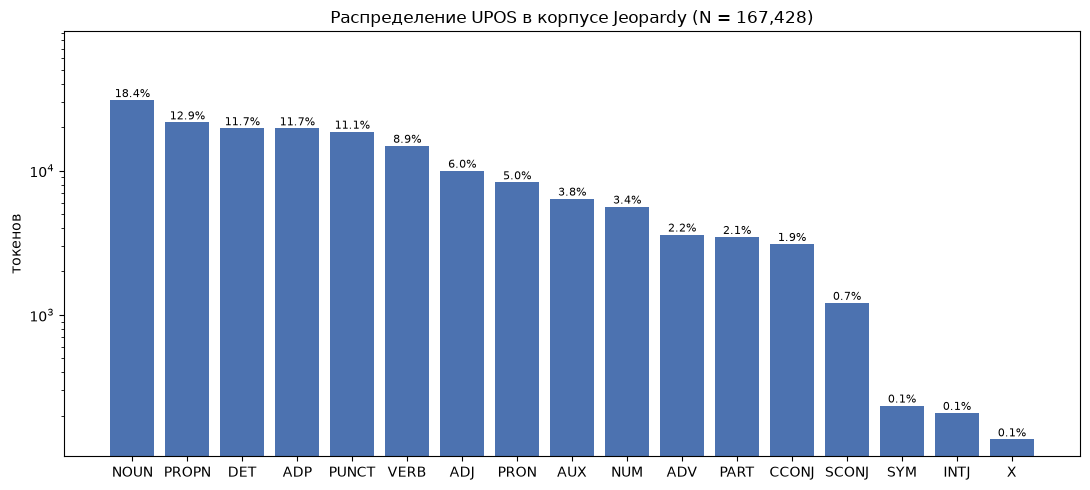

,UPOS,count,share_%
0,NOUN,30813,18.40
1,PROPN,21594,12.90
2,DET,19660,11.74
3,ADP,19627,11.72
4,PUNCT,18610,11.12
5,VERB,14864,8.88
6,ADJ,9982,5.96
7,PRON,8297,4.96
8,AUX,6392,3.82
9,NUM,5625,3.36


In [4]:
pos_flat = [t for r in rows for t in r]
c_upos = Counter(t[2] for t in pos_flat)
N_tok = sum(c_upos.values())

order = c_upos.most_common()
tags  = [t for t, _ in order]
cnts  = [n for _, n in order]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(tags, cnts, color="#4c72b0")
ax.set_ylabel("токенов"); ax.set_yscale("log")
ax.set_title(f"Распределение UPOS в корпусе Jeopardy (N = {N_tok:,})")
for b, n in zip(bars, cnts):
    ax.text(b.get_x()+b.get_width()/2, n*1.05, f"{100*n/N_tok:.1f}%",
            ha="center", fontsize=8)
ax.set_ylim(top=max(cnts)*3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "pos_overall.png"), dpi=110); plt.show()

pd.DataFrame([{"UPOS": t, "count": n, "share_%": round(100*n/N_tok, 2)}
              for t, n in order]).head(12)

### Пункт 2b. Сравнение по классу документа

Класс документов в Jeopardy — **раунд** (`Round`): `Jeopardy!` (обычные
подсказки), `Double Jeopardy!`, `Final Jeopardy!` (полное связное предложение),
`Tiebreaker`. Частоты **ADJ / VERB / INTJ / PROPN / NOUN** по раундам — как
стиль класса меняет морфологический профиль (доли, %, нормированы по токенам).

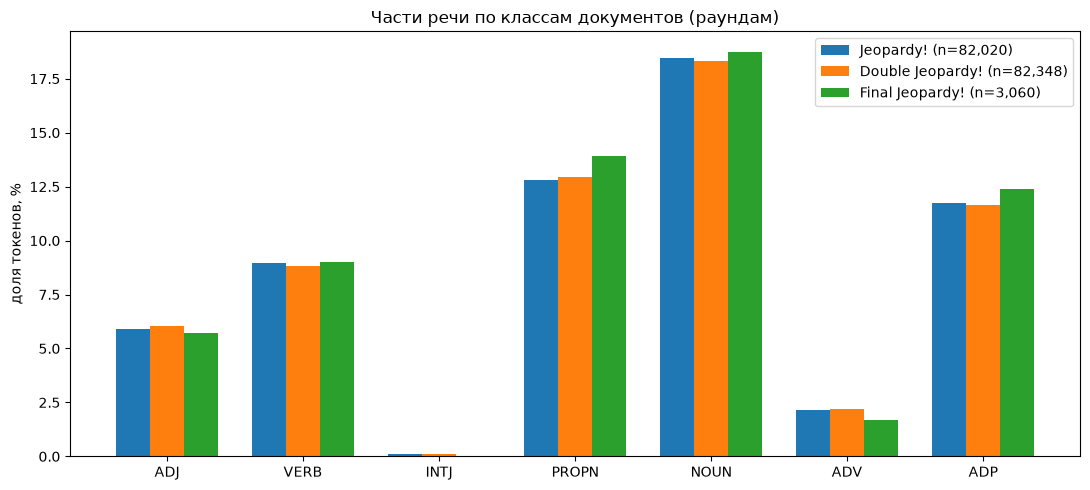

,Jeopardy!,Double Jeopardy!,Final Jeopardy!
ADJ,5.90,6.04,5.72
VERB,8.95,8.81,8.99
INTJ,0.13,0.12,0.00
PROPN,12.83,12.93,13.92
NOUN,18.48,18.31,18.76
ADV,2.13,2.19,1.67
ADP,11.76,11.66,12.39


In [5]:
CLASS_TAGS = ["ADJ", "VERB", "INTJ", "PROPN", "NOUN", "ADV", "ADP"]
rounds = ["Jeopardy!", "Double Jeopardy!", "Final Jeopardy!"]
rates = {r: Counter() for r in rounds}
tot  = Counter()

for r, row in zip(sample10k["Round"], rows):
    if r not in rounds:
        continue
    tot[r] += len(row)
    for t in row:
        if t[2] in CLASS_TAGS:
            rates[r][t[2]] += 1

mat = pd.DataFrame({r: {tg: 100*rates[r][tg]/tot[r] for tg in CLASS_TAGS} for r in rounds})

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(CLASS_TAGS)); w = 0.25
for j, r in enumerate(rounds):
    ax.bar(x + j*w, mat[r], w, label=f"{r} (n={tot[r]:,})")
ax.set_xticks(x + w); ax.set_xticklabels(CLASS_TAGS)
ax.set_ylabel("доля токенов, %"); ax.legend()
ax.set_title("Части речи по классам документов (раундам)")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "pos_by_round.png"), dpi=110); plt.show()
mat.round(2)

Дополнительно — категории как подклассы: сравним долю **ADJ** и **VERB** в
категориях-крайностях (топ категорий по доле ADJ vs по доле VERB, категории с
≥150 вопросами в выборке).

In [6]:
cat_rates = {}
cat_tot = Counter()
sample10k["cat_norm"] = sample10k["Category"].str.strip().str.upper()
for (cat, rnd), row in zip(zip(sample10k["cat_norm"], sample10k["Round"]), rows):
    cat_tot[cat] += len(row)
    for t in row:
        if t[2] in ("ADJ", "VERB", "INTJ"):
            cat_rates.setdefault(cat, Counter())[t[2]] += 1

tab = pd.DataFrame([{"Category": c,
                     "ADJ_%": round(100*cat_rates.get(c, Counter())["ADJ"]/cat_tot[c], 2),
                     "VERB_%": round(100*cat_rates.get(c, Counter())["VERB"]/cat_tot[c], 2),
                     "INTJ_%": round(100*cat_rates.get(c, Counter())["INTJ"]/cat_tot[c], 3),
                     "n_tok": cat_tot[c]}
                    for c in cat_tot if cat_tot[c] >= 150])
print("— топ-6 категорий по ADJ —"); print(tab.sort_values("ADJ_%", ascending=False).head(6).to_string(index=False))
print("— топ-6 категорий по VERB —"); print(tab.sort_values("VERB_%", ascending=False).head(6).to_string(index=False))

— топ-6 категорий по ADJ —
             Category  ADJ_%  VERB_%  INTJ_%  n_tok
           DEAD LINES  11.25    6.88     0.0    160
           ADJECTIVES   9.01    8.15     0.0    233
DEPT. OF THE INTERIOR   8.88    9.47     0.0    169
         TV OR NOT TV   8.81   10.06     0.0    159
   GETTING SCIENTIFIC   8.75    7.50     0.0    160
              AUTHORS   8.67    7.14     0.0    196
— топ-6 категорий по VERB —
       Category  ADJ_%  VERB_%  INTJ_%  n_tok
BOOKS & AUTHORS   5.46   12.57   0.546    183
  THE 50 STATES   5.24   12.57   0.000    191
  ANIMAL GROUPS   3.37   12.36   0.000    178
DAS KAPITALISTS   4.28   12.30   0.000    187
      ON THE GO   3.91   11.73   0.000    179
            ART   5.10   11.46   0.637    157


### Пункт 2c. Ошибки тэггера на шуме и сленге (≥5 примеров)

Эвристика-сканер флагирует токены «подозрительной формы» (эмодзи-подобные,
числовые, акронимы с точками, амперсанд-конструкции, всё КАПС) и печатает их
разметку целиком — видно, как специфика TV-кворума ломает UD-разметку.

In [7]:
EMOJI_LIKE = re.compile(r"[;:8=][-^*'\\\"]?[)(pdP$@oO3<|~/]+")
NUMISH     = re.compile(r"^\$?\d[\d,.]*$")
ABBR_DOT   = re.compile(r"^(?:[A-Za-z]\.){2,}[A-Za-z]?\.?$")
CAPS       = re.compile(r"^[A-Z]{4,}[!?&]*$")

def suspect(tok_text: str) -> str | None:
    if EMOJI_LIKE.fullmatch(tok_text): return "эмодзи/смайлик"
    if NUMISH.fullmatch(tok_text):      return "число/деньги"
    if ABBR_DOT.fullmatch(tok_text):    return "акроним с точками"
    if tok_text == "&":                 return "амперсанд (HTML-остаток)"
    if CAPS.fullmatch(tok_text):        return "КАПС-акроним/фраза"
    return None

hits = []
for sent in rows:
    for (txt, lem, upos, xpos) in sent:
        why = suspect(txt)
        if why:
            hits.append((why, txt, lem, upos, xpos, " ".join(t[0] for t in sent)))
print("всего подозрительных токенов в выборке:", len(hits))
seen, picked = set(), []
for why, txt, lem, upos, xpos, ctx in hits:
    key = (why, txt.lower())
    if key in seen: continue
    seen.add(key); picked.append((why, txt, lem, upos, xpos, ctx))
print(f"уникальных форм: {len(picked)}; показываем первые 12")
for w, txt, lem, upos, xpos, ctx in picked[:12]:
    print(f"[{w:22s}] {txt!r:18s} -> lemma={lem!r} UPOS={upos} XPOS={xpos}")
    print("    ctx:", ctx[:110])

всего подозрительных токенов в выборке: 7666
уникальных форм: 939; показываем первые 12
[амперсанд (HTML-остаток)] '&'                -> lemma='&' UPOS=CCONJ XPOS=CC
    ctx: It denotes the Catholic revival & response to Martin Luther that began in the 16th century Prime Minister Kim 
[число/деньги          ] '1866'             -> lemma='1866' UPOS=NUM XPOS=CD
    ctx: He was knighted in 1866 not for his temperature scale , but for helping develop the transatlantic cable A Brit
[число/деньги          ] '2'                -> lemma='2' UPOS=NUM XPOS=CD
    ctx: He was knighted in 1866 not for his temperature scale , but for helping develop the transatlantic cable A Brit
[число/деньги          ] '1'                -> lemma='1' UPOS=NUM XPOS=CD
    ctx: He was knighted in 1866 not for his temperature scale , but for helping develop the transatlantic cable A Brit
[число/деньги          ] '1996'             -> lemma='1996' UPOS=NUM XPOS=CD
    ctx: It s status as a major port led to its Engl

## Пункт 3. Dependency parsing + визуализация

Конвейер `tokenize,pos,lemma,depparse` на подвыборке 2 000 предложений (депарсер
самый дорогой; GPU). Для визуализации — 10 предложений **средней длины** (10–16
слов, без спецтокенов). Схема связей: дуговая диаграмма (head → dependent,
подпись —rels UD) + текстовое дерево UD (`dep2txt`).

In [8]:
import gc, torch

# освобождаем VRAM после POS-пайплайна (модели POS больше не нужны)
del nlp_pos
gc.collect()
torch.cuda.empty_cache()

nlp_dep = stanza.Pipeline(lang="en",
                          processors="tokenize,pos,lemma,depparse",
                          use_gpu=(DEVICE == "cuda"), verbose="ERROR")

# та же пакетная форма, что и в POS-конвейере: ОДНА строка, документ = строка
# маленькие чанки + очистка кэша между ними — деппарсер (BiLSTM) жаден до VRAM
sub = sample10k["text"].iloc[:2000].tolist()
docs_dep = []
CHUNK_DEP = 200
for i in range(0, len(sub), CHUNK_DEP):
    chunk = [t.replace("\n", " ") for t in sub[i:i+CHUNK_DEP]]
    docs_dep.append(nlp_dep("\n".join(chunk)))
    torch.cuda.empty_cache()
    print(f"depparse: {min(i+CHUNK_DEP, len(sub))}/{len(sub)}")
sentences = [s for doc in docs_dep for s in doc.sentences]
print("предложений с деревом:", len(sentences))

2026-11-20 16:40:43 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2026-11-20 16:40:44 INFO: Downloaded file to /home/miryz/.cache/stanza/1.15.0/resources/resources.json


2026-11-20 16:40:44 WARNING: Language en package default expects mwt, which has been added


2026-11-20 16:40:45 INFO: Loading these models for language: en (English):
| Processor | Package           |
---------------------------------
| tokenize  | combined_nocharlm |
| mwt       | combined          |
| pos       | combined_charlm   |
| lemma     | combined_nocharlm |
| depparse  | combined_charlm   |



2026-11-20 16:40:45 INFO: Using device: cpu


2026-11-20 16:40:45 INFO: Loading: tokenize


... (11 outputs left out)

depparse: 1400/2000


depparse: 1600/2000


depparse: 1800/2000


depparse: 2000/2000
предложений с деревом: 922


### Визуализация: 10 предложений средней длины

Одно предложение = отдельная картинка `dep_tree_01.png` … `dep_tree_10.png`
(ширина пропорциональна длине предложения): слово + UPOS, дуга head→dependent
с подписью деппенденции.

кандидатов: 142


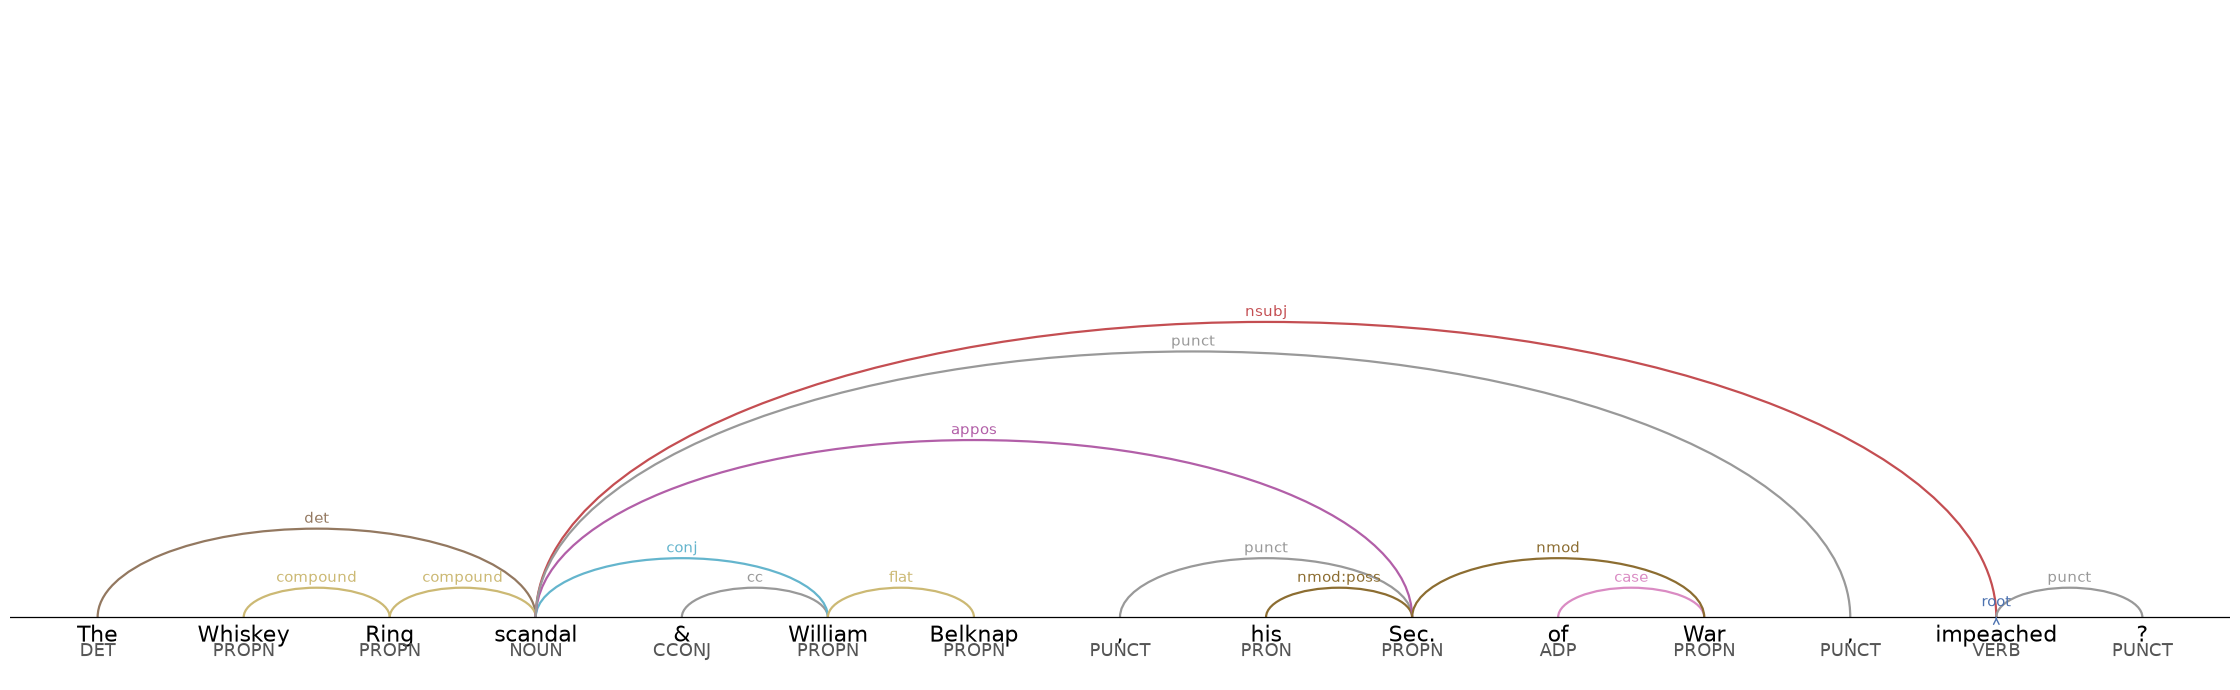

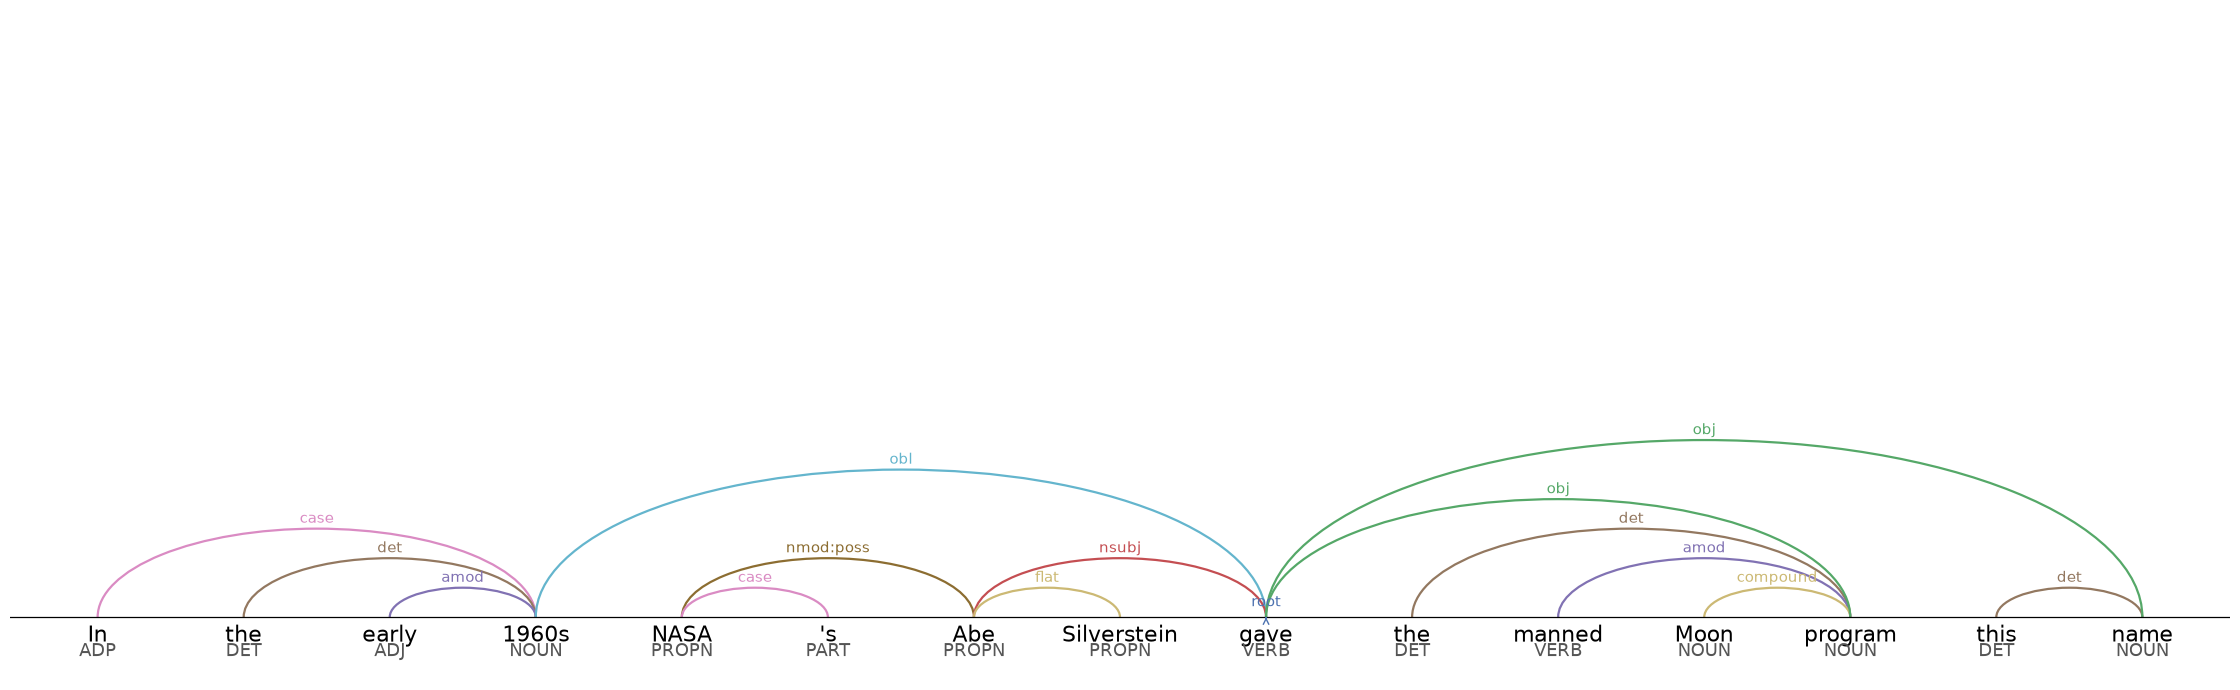

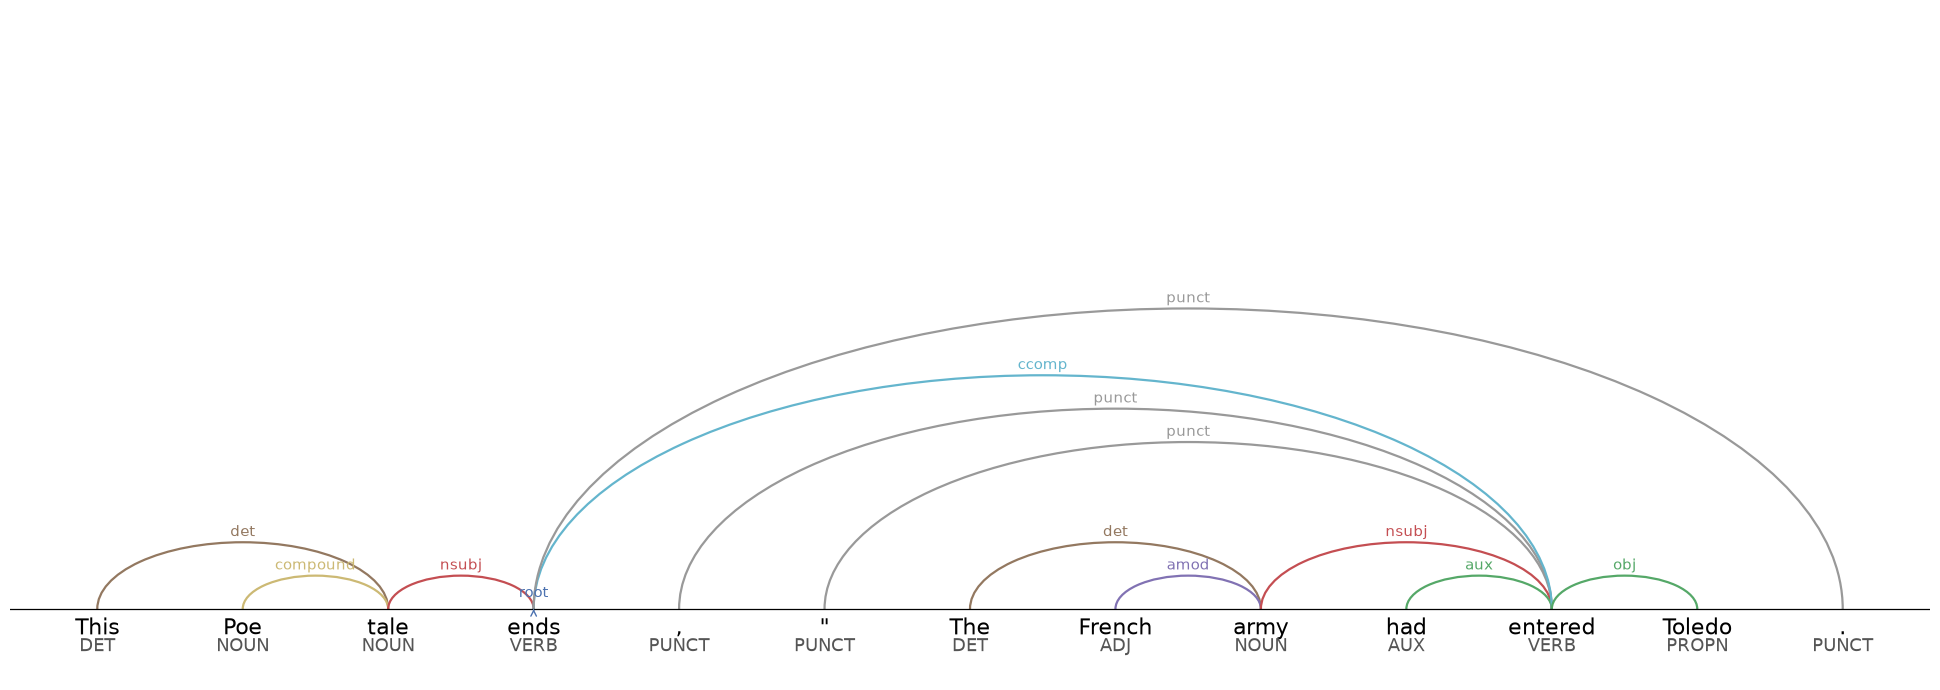

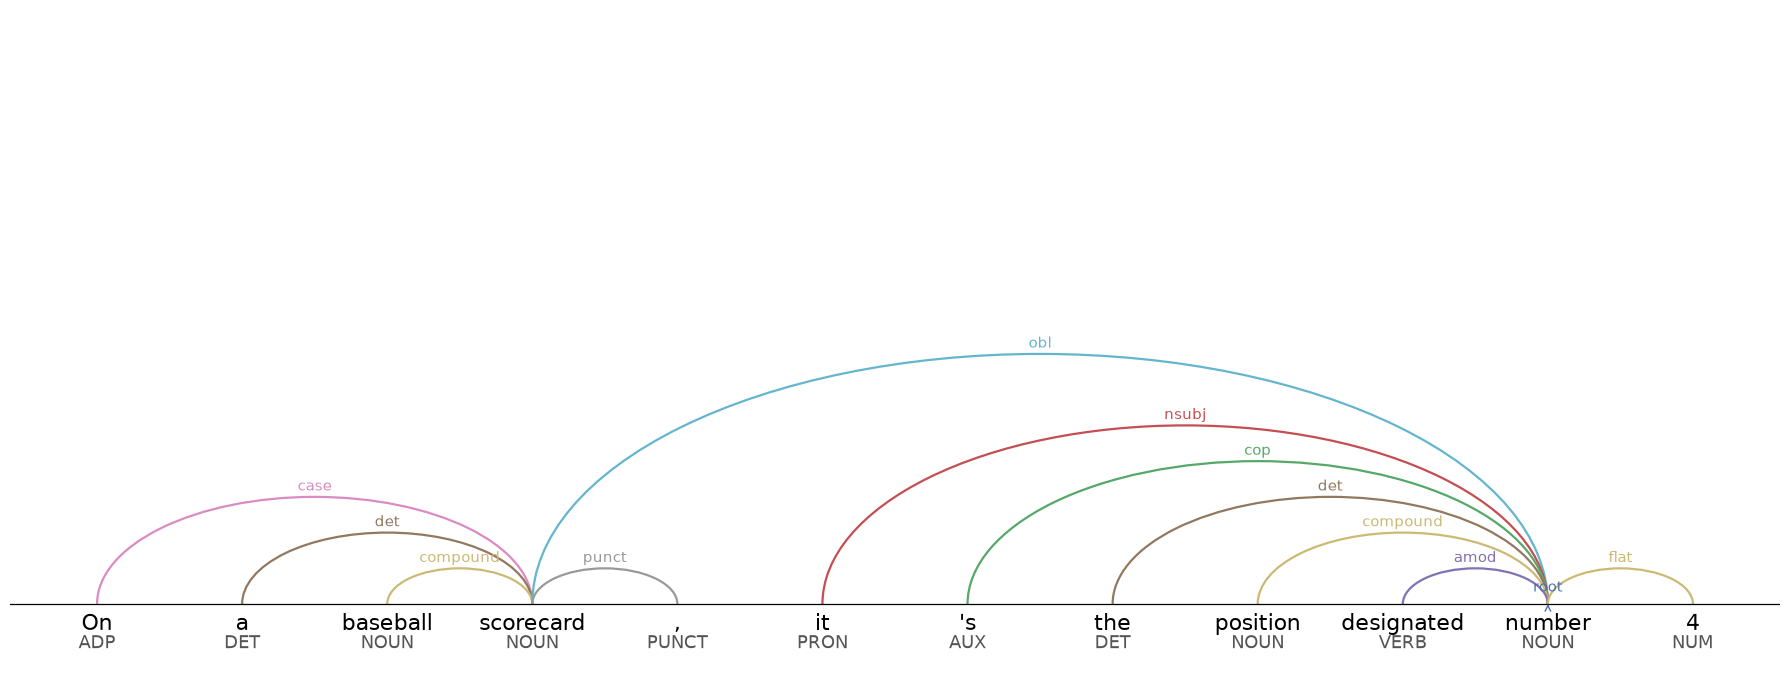

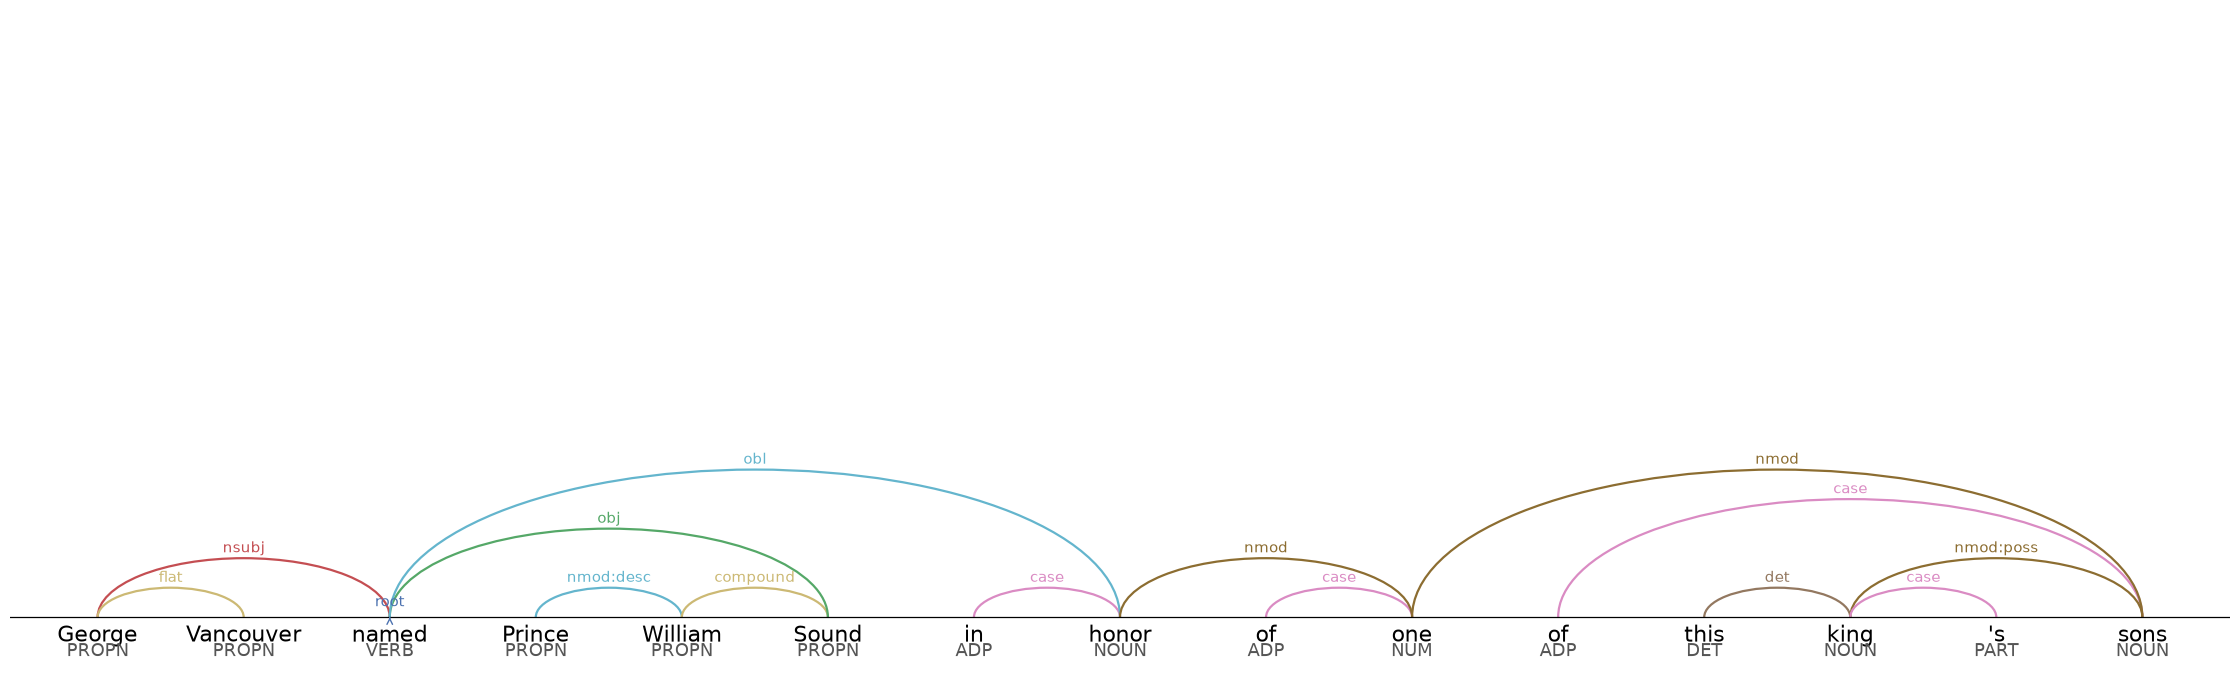

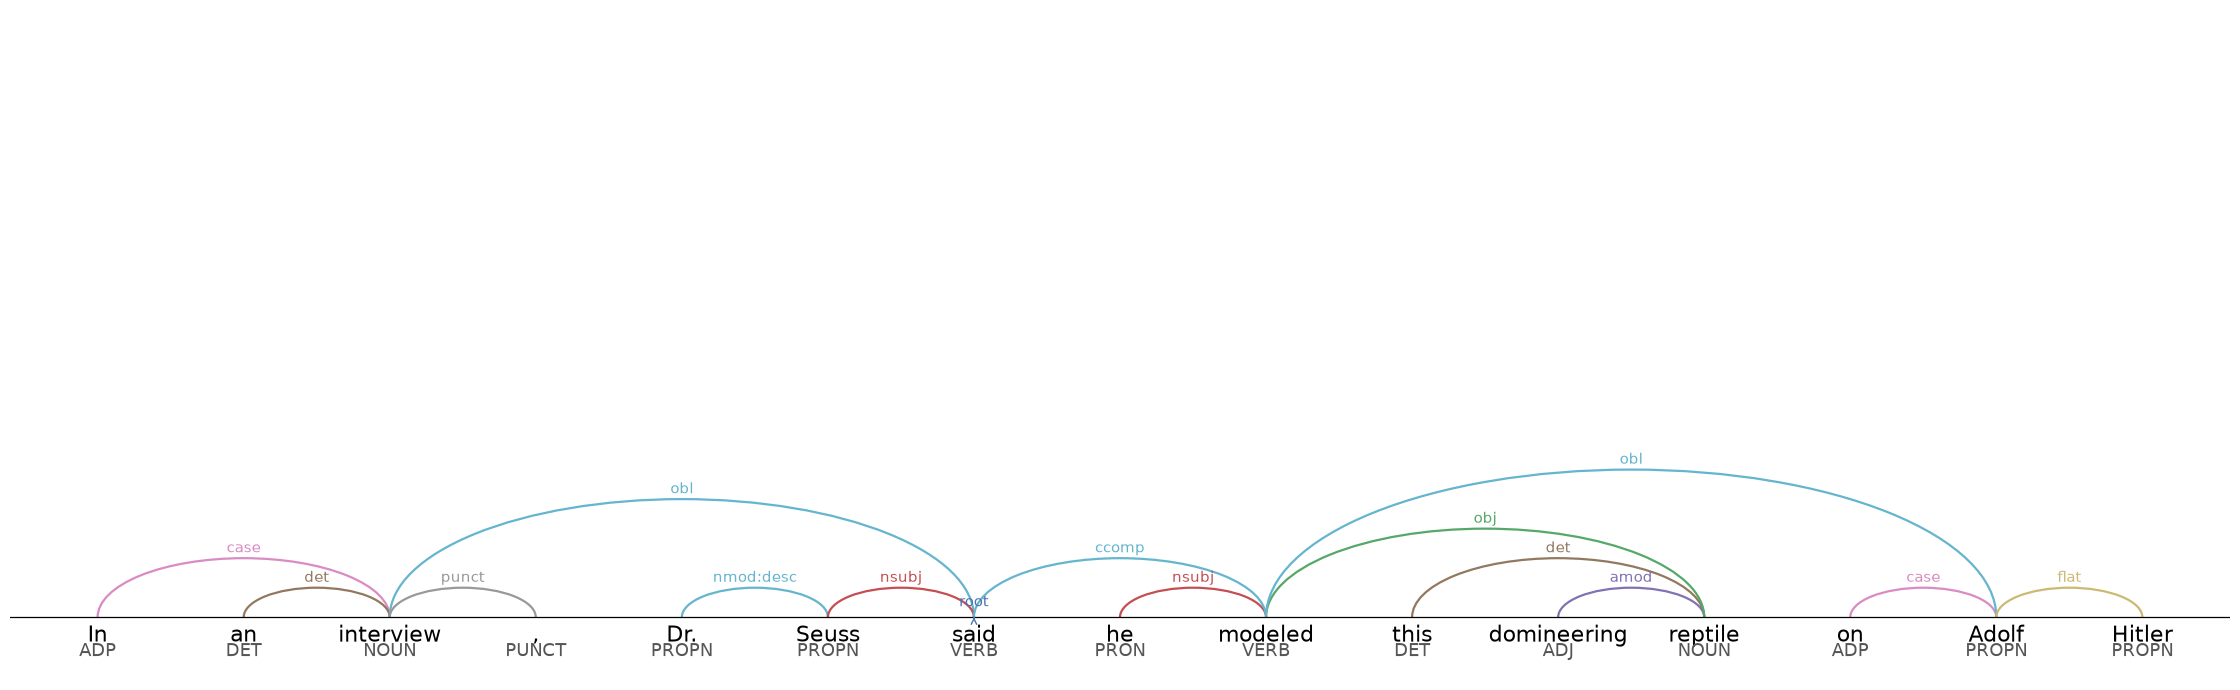

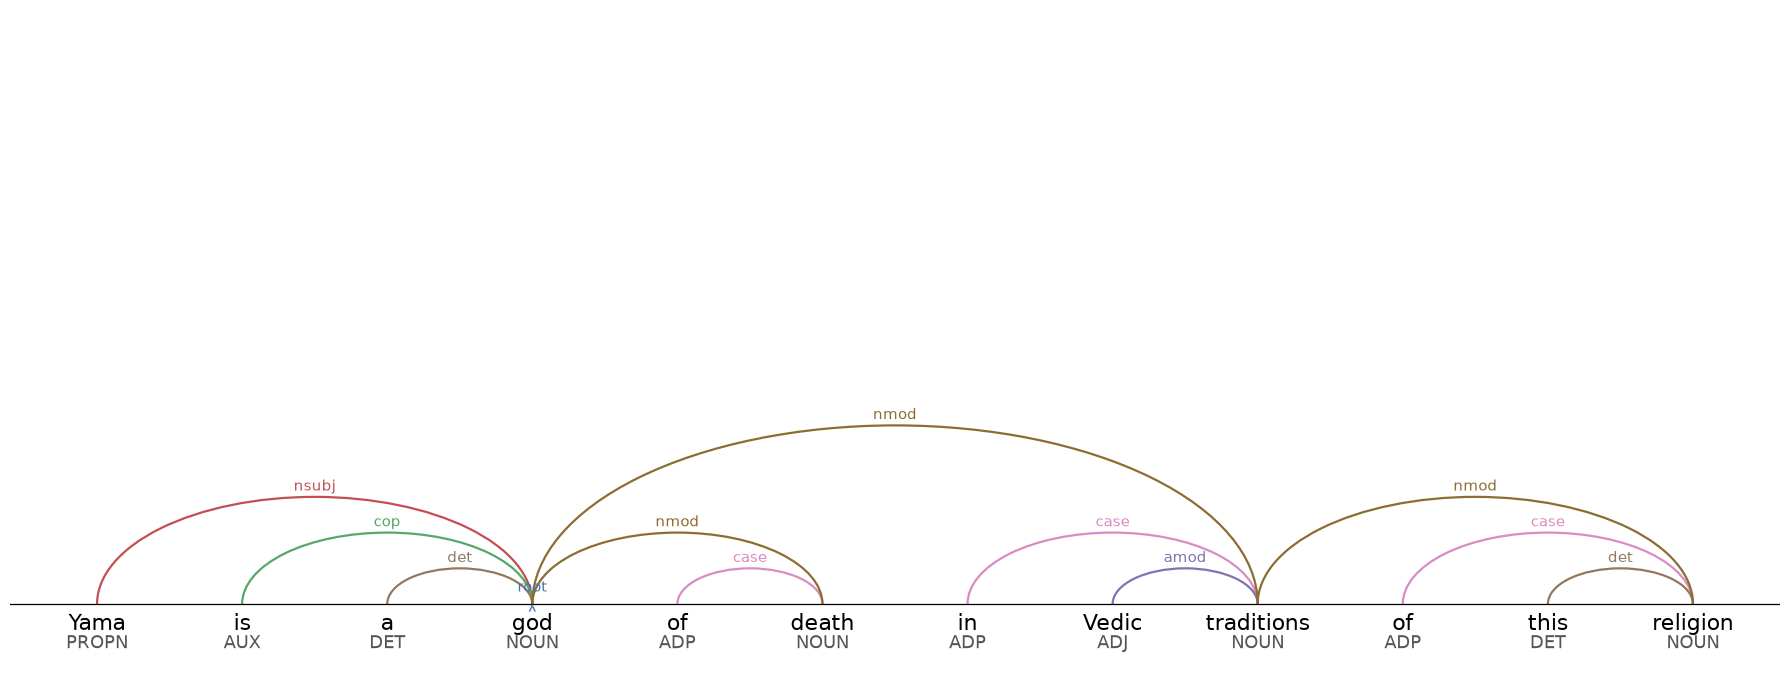

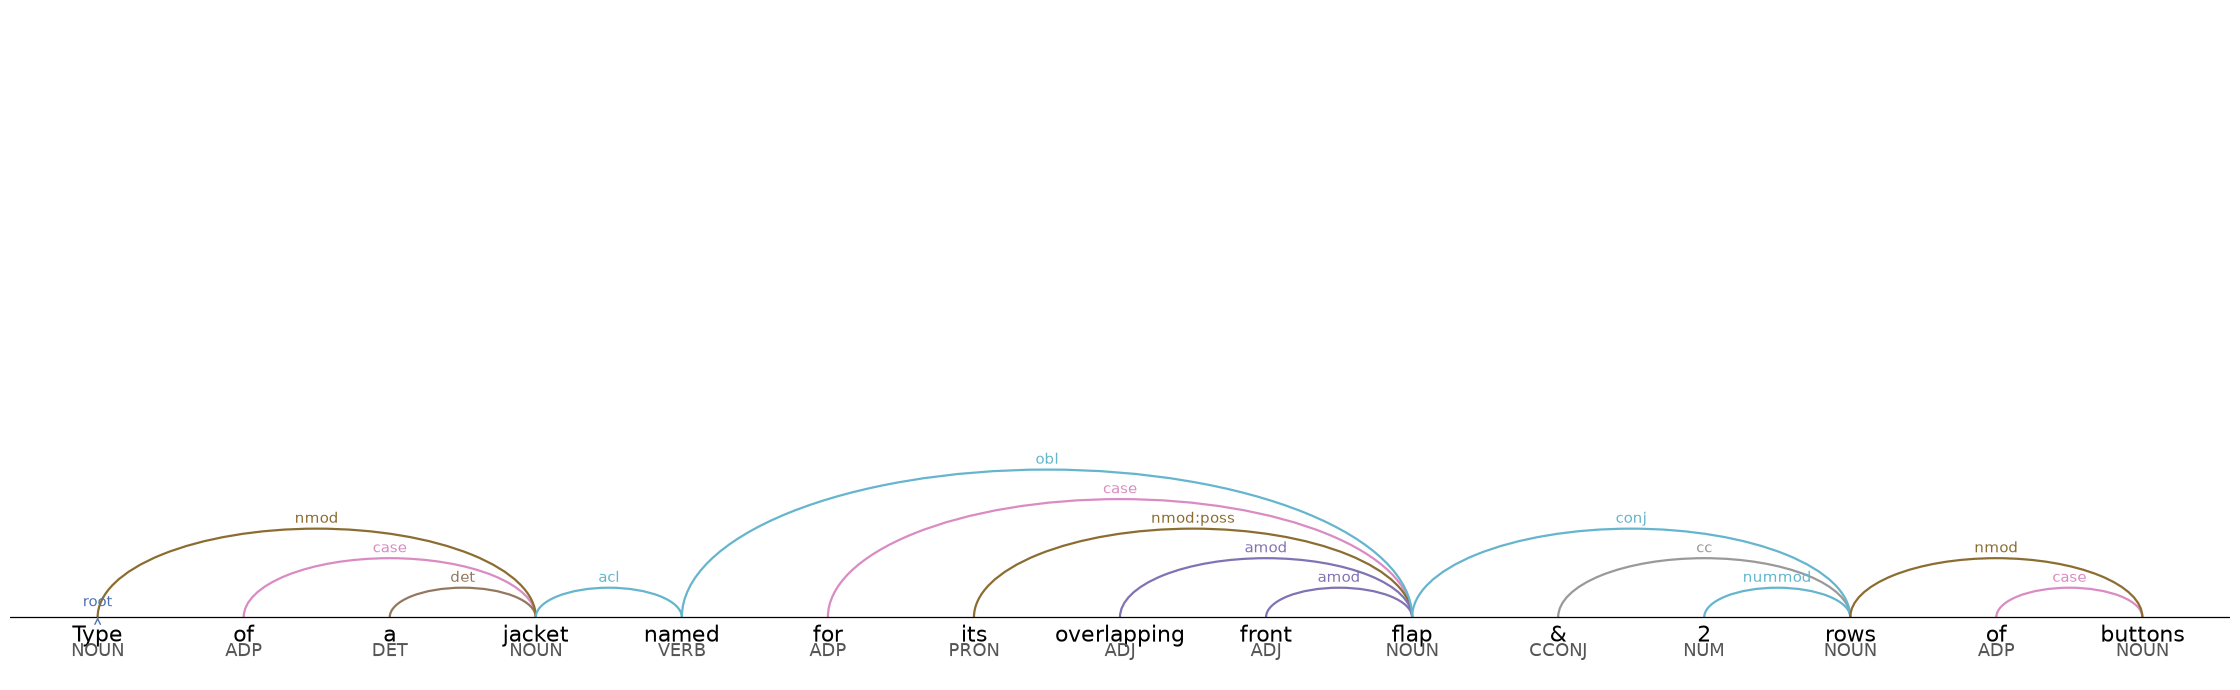

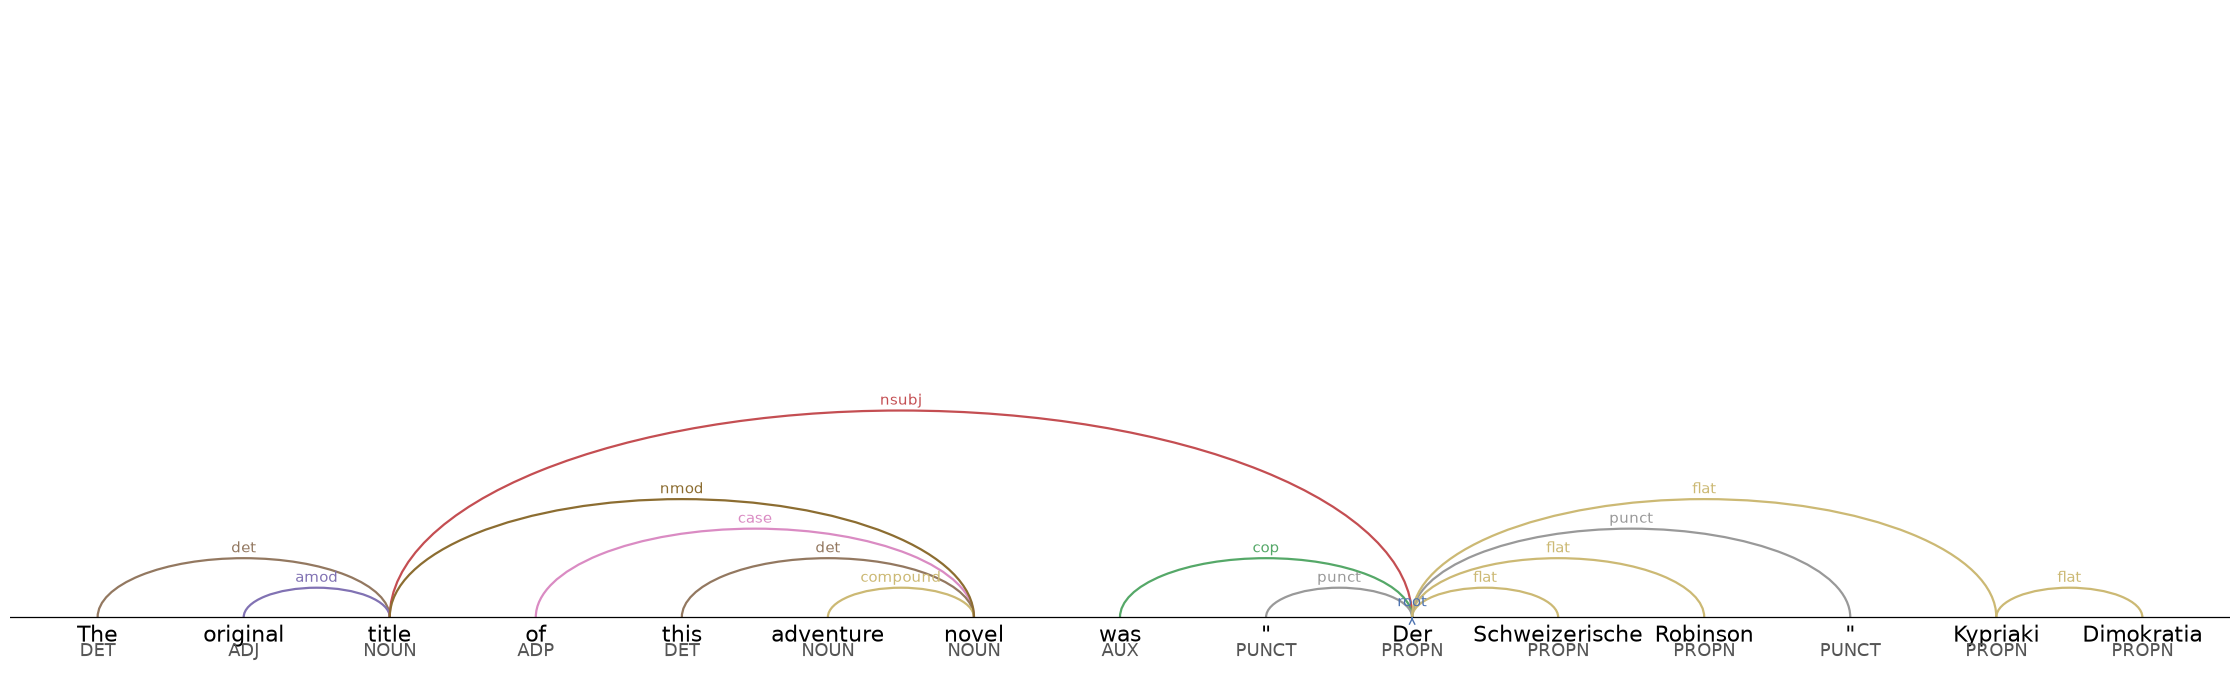

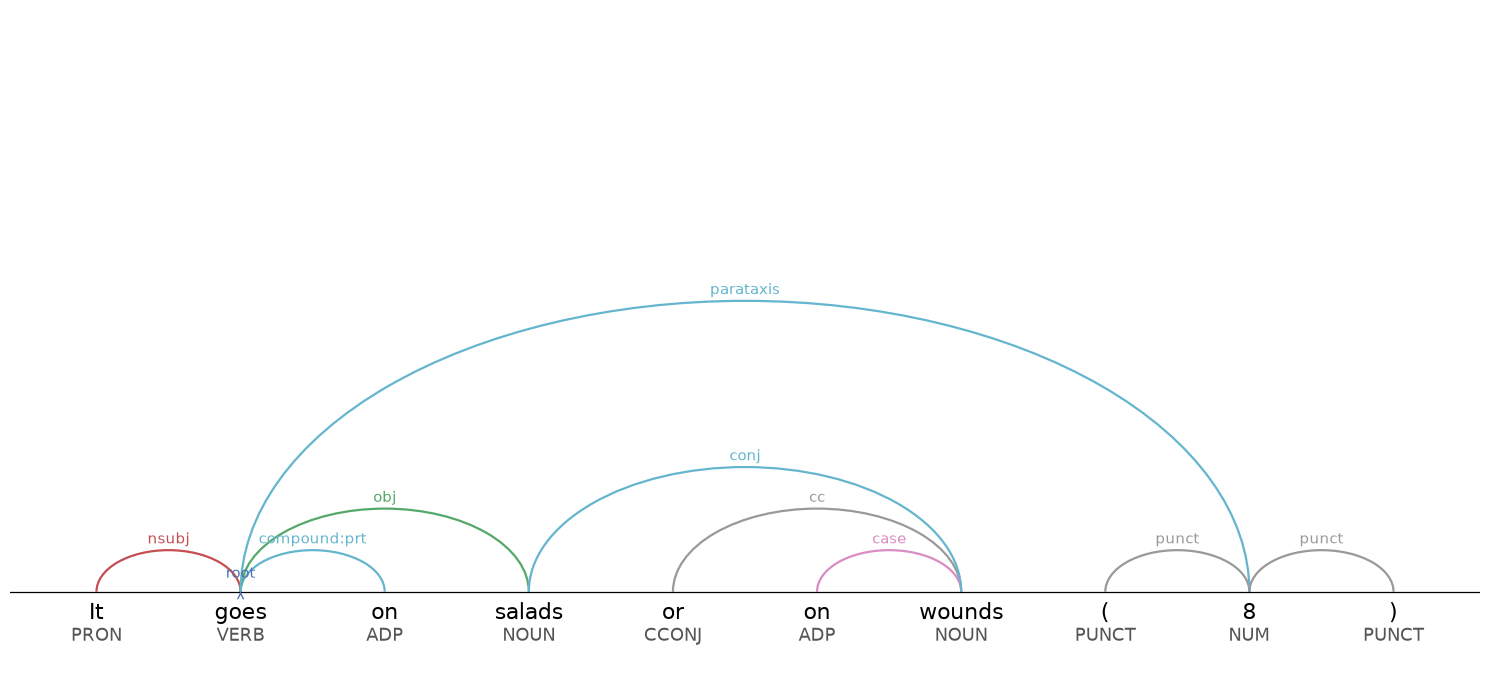

In [9]:
REL_COLOR = {"nsubj": "#c44e52", "nsubjpass": "#c44e52", "root": "#4c72b0",
             "aux": "#55a868", "cop": "#55a868", "amod": "#8172b3",
             "det": "#937860", "case": "#da8bc3", "nmod": "#8c6d31",
             "nmod:poss": "#8c6d31", "compound": "#ccb974",
             "obj": "#55a868", "iobj": "#55a868", "advcl": "#64b5cd",
             "advmod": "#64b5cd", "nummod": "#64b5cd", "appos": "#b25fa8",
             "flat": "#ccb974", "fixed": "#ccb974", "orphan": "#999999",
             "punct": "#999999", "cc": "#999999", "mark": "#999999",
             "xcomp": "#e5c471", "compound:nn": "#ccb974"}

def draw_arc(ax, x1, x2, label, color, lw=1.6):
    x_lo, x_hi = sorted((x1, x2))
    mid, r = (x_lo+x_hi)/2, (x_hi-x_lo)/2
    ax.add_patch(mpatches.Arc((mid, 0), 2*r, 1.6*r, theta1=0, theta2=180,
                              color=color, lw=lw))
    # подпись деппенденции на вершине дуги, цветом связи
    ax.text(mid, 0.8*r + 0.03, label, ha="center", va="bottom",
            fontsize=11, color=color)

def draw_dep(s, ax):
    toks = [w for w in s.words]
    ax.axhline(0, color="black", lw=.9)
    for w in toks:
        x = w.id
        ax.text(x, -0.10, w.text, ha="center", va="top", fontsize=16)
        ax.text(x, -0.34, w.upos, ha="center", va="top", fontsize=13, color="#555")
        color = REL_COLOR.get(w.deprel, "#64b5cd")
        if w.head == 0:
            ax.annotate("", xy=(x, 0), xytext=(x, -0.05),
                        arrowprops=dict(arrowstyle="->", color=REL_COLOR["root"]))
            ax.text(x, 0.10, "root", ha="center", va="bottom",
                    fontsize=11, color=REL_COLOR["root"])
        else:
            draw_arc(ax, w.head, x, w.deprel, color)
    n = len(toks)
    ax.set_xlim(0.4, n+0.6); ax.set_ylim(-0.85, max(2.0, 1.05*n/2 + 0.35))
    ax.axis("off")

# 10 предложений средней длины 10–16 слов (UD-узлы), без спецтокенов
cands = [s for s in sentences
         if 10 <= len(s.words) <= 16
         and "[URL]" not in " ".join(w.text for w in s.words)]
print("кандидатов:", len(cands))
rng = random.Random(SEED)
picks = rng.sample(cands, 10)

# одно предложение = одна картинка; ширина пропорциональна числу слов
for i, s in enumerate(picks, start=1):
    n = len(s.words)
    fig, ax = plt.subplots(1, 1, figsize=(max(11, 1.5*n), 7))
    draw_dep(s, ax)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, f"dep_tree_{i:02d}.png"), dpi=110)
    plt.show()   # картинка отображается прямо в ноутбуке

Те же 10 предложений в текстовом UD-дереве (обход от корня; отступ = глубина;
узел = `текст (UPOS/deprel)`):

In [10]:
def children_map(sent):
    """Word.children в stanza 1.15 нет — строим map id -> [Word] по head."""
    ws = list(sent.words)
    ch = defaultdict(list)
    for w in ws:
        ch[w.head].append(w)
    for k in ch:
        ch[k].sort(key=lambda w: w.id)
    return ws, ch

def render_ud(sent):
    """Текстовое UD-дерево: обход от root, отступ = глубина, узел = text (upos/deprel)."""
    ws, ch = children_map(sent)
    roots = ch[0]
    lines = []
    def walk(w, depth):
        lines.append("  " * depth + f"{w.text} ({w.upos}/{w.deprel})")
        for c in ch[w.id]:
            walk(c, depth + 1)
    for r in roots:
        walk(r, 0)
    return "\n".join(lines)

for s in picks:
    print(" ".join(w.text for w in s.words))
    print(render_ud(s))
    print("=" * 80)

The Whiskey Ring scandal & William Belknap , his Sec. of War , impeached ?
impeached (VERB/root)
  scandal (NOUN/nsubj)
    The (DET/det)
    Ring (PROPN/compound)
      Whiskey (PROPN/compound)
    William (PROPN/conj)
      & (CCONJ/cc)
      Belknap (PROPN/flat)
    Sec. (PROPN/appos)
      , (PUNCT/punct)
      his (PRON/nmod:poss)
      War (PROPN/nmod)
        of (ADP/case)
    , (PUNCT/punct)
  ? (PUNCT/punct)
In the early 1960s NASA 's Abe Silverstein gave the manned Moon program this name
gave (VERB/root)
  1960s (NOUN/obl)
    In (ADP/case)
    the (DET/det)
    early (ADJ/amod)
  Abe (PROPN/nsubj)
    NASA (PROPN/nmod:poss)
      's (PART/case)
    Silverstein (PROPN/flat)
  program (NOUN/obj)
    the (DET/det)
    manned (VERB/amod)
    Moon (NOUN/compound)
  name (NOUN/obj)
    this (DET/det)
This Poe tale ends , " The French army had entered Toledo .
ends (VERB/root)
  tale (NOUN/nsubj)
    This (DET/det)
    Poe (NOUN/compound)
  entered (VERB/ccomp)
    , (PUNCT/punct)


## Пункт 4. Алгоритм извлечения смысловых пар из дерева

Функция `extract_pairs(sentence)` обходит узлы дерева и собирает:

* **[аспект + оценка]** — голова NOUN/PROPN с зависимостями `amod`, `amod:rel`,
  `acl`, `nmod:poss` от ADJ (аналог «экран яркий»);
* **[субъект + действие]** — VERB-предикат (не инфинитив/вспомогательный) с
  `nsubj`/`nsubjpass` (аналог «акции упали»).

In [11]:
ADJ_REL  = {"amod", "acl", "nmod:poss", "nmod:tmod"}
SUBJ_REL = {"nsubj", "nsubjpass"}

def extract_pairs(sent):
    """Обход UD-дерева: (аспект+оценка), (субъект+действие). Узлы = sent.words,
    дети строятся картой id -> [Word] по head (у Word нет атрибута children)."""
    ws, ch = children_map(sent)
    aspect, action = [], []
    for w in ws:
        # [аспект + оценка]: голова-существительное + прилагательное-модификатор
        if w.upos in ("NOUN", "PROPN"):
            for d in ch[w.id]:
                if d.deprel in ADJ_REL and d.upos == "ADJ":
                    aspect.append((w.text.lower(), d.text.lower()))
        # [субъект + действие]: глагол-предикат с подлежащим
        if w.upos == "VERB":
            for c in ch[w.id]:
                if c.deprel in SUBJ_REL and c.upos not in ("PRON", "NUM"):
                    action.append((c.text.lower(), w.lemma.lower()))
    return aspect, action

c_aspect, c_action = Counter(), Counter()
n_sent_with = Counter()
for s in sentences:
    a, v = extract_pairs(s)
    c_aspect.update(a); c_action.update(v)
    if a: n_sent_with["aspect"] += 1
    if v: n_sent_with["action"] += 1

print(f"предложений: {len(sentences)}; с [аспект+оценка]: {n_sent_with['aspect']}, "
      f"с [субъект+действие]: {n_sent_with['action']}")
print("уникальных аспект-пар:", len(c_aspect), "; субъект-действие:", len(c_action))

предложений: 922; с [аспект+оценка]: 676, с [субъект+действие]: 574
уникальных аспект-пар: 1537 ; субъект-действие: 922


## Пункт 5. Топ-20 пар и анализ

In [12]:
pd.set_option("display.max_colwidth", 60)
top_a = pd.DataFrame([(f"{a} | {b}", n) for (a, b), n in c_aspect.most_common(20)],
                     columns=["аспект | оценка", "частота"])
top_v = pd.DataFrame([(f"{s} | {v}", n) for (s, v), n in c_action.most_common(20)],
                     columns=["субъект | действие", "частота"])
top_a.to_csv(os.path.join(OUT, "top_aspect_pairs.csv"), index=False)
top_v.to_csv(os.path.join(OUT, "top_action_pairs.csv"), index=False)
print("— [аспект + оценка] —"); display(top_a)
print("— [субъект + действие] —"); display(top_v)

— [аспект + оценка] —


,аспект | оценка,частота
0,york | new,14
1,minister | prime,9
2,name | first,6
3,court | supreme,5
4,words | last,4
5,house | white,4
6,century | 20th,4
7,park | national,4
8,lady | first,4
9,minister | british,3


— [субъект + действие] —


,субъект | действие,частота
0,name | mean,9
1,name | come,8
2,some | say,5
3,sarah | report,4
4,word | mean,3
5,duties | include,2
6,adjective | mean,2
7,film | feature,2
8,jimmy | report,2
9,sarah | deliver,2


## Пункт 6. Разрешение анафоры (rule-based)

Местоимения 3 л. англ. корпуса: **he / she / it / they** (+ possessive his/her/its/their).
Правило выбора антецедента:

1. **Согласование (морфология UD-признаков):**
   * `he` → кандидат с числом `Singular`, класс «мужской»: NNP из мужского
     словаря имён либо `MALE_LEX` (man, king, president…);
   * `she` → женский словарь (`FEMALE_LEX`);
   * `it` → неодушевлённый `NN` (сингл, не в лексиконе людей);
   * `they` → **plural** (`NNS` — множественное число по UD XPOS).
2. **Синтаксическая дистанция:** линейное расстояние `pos(pron) − pos(cand)`;
   прецедентные (предшествующие) кандидаты получают приоритет, последующие —
   штраф +100 (анафора смотрит «назад»).
3. Победитель — min(штраф + |расстояние|); местоимение заменяется антецедентом.

Ограничение объёма:Candidates ищутся внутри предложения (корпус односложный,
антецедент обычно в том же предложении).

In [13]:
MALE_LEX   = set("man boy king president emperor prince actor author knight hero "
                  "god devil jesus moses noah odysseus hercules zeus apollo neptune mars "
                  "galileo einstein napoleon shakespeare mozart beethoven hitler stalin "
                  "gandhi churchill caesar augustus cicero plato aristotle "
                  "socrates darwin newton "
                  "george john james robert william richard joseph charles stephen "
                  "brian bruce fred mark paul peter henry thomas edward donald bill "
                  "jimmy elvis abe jack tom bob dick frank geoffrey jeffrey leo "
                  "leonard martin michael david daniel anthony kevin scott".split())
FEMALE_LEX = set("woman girl queen empress princess actress mary elizabeth victoria "
                 "cleopatra joan athena hera aphrodite venus diana minerva cinderella "
                 "nun countess duchess "
                 "helen margaret anne jane alice catherine elinor isabel sophia "
                 "martha dorothy ruth esther abigail beatrice carol dorothy evelyn "
                 "frances grace hannah hilary judith katharine laura louise "
                 "mildred nicole olivia philippa rose susan virginia wilhelmina".split())
PERSON     = MALE_LEX | FEMALE_LEX
PRON_GENDER = {"he": "male", "she": "female", "it": "neuter", "they": "plural"}

def candidates_for(gender: str, ws):
    """Существительные-кандидаты, согласованные с родом/числом местоимения."""
    out = []
    for t in ws:
        txt = t.text.lower()
        if t.upos not in ("NOUN", "PROPN"):
            continue
        plural = t.xpos == "NNS"
        sing   = t.xpos in ("NN", "NNP")
        if gender == "plural":
            ok = plural
        elif gender == "neuter":
            ok = sing and txt not in PERSON and t.upos == "NOUN"
        elif gender == "male":
            ok = sing and txt in MALE_LEX
        elif gender == "female":
            ok = sing and txt in FEMALE_LEX
        else:
            ok = False
        if ok:
            out.append(t)
    return out

def resolve_sentence(sent):
    """[(pron_tok, antecent_tok, score)] для предложения (узлы = sent.words)."""
    ws = list(sent.words)
    res = []
    for t in ws:
        gender = PRON_GENDER.get(t.text.lower().rstrip("."))
        if not gender:
            continue
        best, best_score = None, None
        for c in candidates_for(gender, ws):
            if c.id == t.id:
                continue
            dist = t.id - c.id
            score = (0 if dist > 0 else 100) + abs(dist)   # прецедент впереди
            if best_score is None or score < best_score:
                best, best_score = c, score
        if best is not None:
            res.append((t, best, best_score))
    return res

def apply_resolution(sent):
    """Строка-предложение → строка с заменёнными местоимениями + трассировка."""
    ws = list(sent.words)
    res = resolve_sentence(sent)
    id2idx = {w.id: k for k, w in enumerate(ws)}
    out = [w.text for w in ws]
    trace = []
    for pron_tok, ant, score in res:
        out[id2idx[pron_tok.id]] = ant.text
        trace.append((pron_tok.text, ant.text, ant.upos, ant.xpos, score))
    return " ".join(w.text for w in ws), " ".join(out), trace

pron_pats = re.compile(r"\b(he|she|it|they)\b", re.I)
pool = [s for s in sentences
        if pron_pats.search(" ".join(w.text for w in s.words))]
print("предложений с местоимениями 3 л.:", len(pool))

# статистика: сколько местоимений реально разрешается правилом
n_pron = n_resolved = 0
rng = random.Random(SEED + 1)
demo = rng.sample(pool, min(80, len(pool)))
shown, artifacts = 0, []
for s in pool:
    for t in s.words:
        g = PRON_GENDER.get(t.text.lower().rstrip("."))
        if g and candidates_for(g, list(s.words)):
            n_pron += 1
            n_resolved += 1
print(f"местоимений 3 л. всего: {n_pron}; с найденным антецедентом: {n_resolved}")

for s in demo:
    orig, new, trace = apply_resolution(s)
    if not trace:
        continue
    shown += 1
    print(f"--- пример {shown}")
    print("  было:  ", orig)
    print("  стало:  ", new)
    for p, a, upos, xpos, sc in trace:
        print(f"    {p} → {a}  (согл. {upos}/{xpos}, score={sc})")
    artifacts.append(f"было:  {orig}\nстало:  {new}\n" +
                     "\n".join(f"    {p} -> {a} ({upos}/{xpos}, score={sc})"
                               for p, a, upos, xpos, sc in trace) + "\n")
    if shown >= 8:
        break
with open(os.path.join(OUT, "anaphora_examples.txt"), "w", encoding="utf-8") as f:
    f.write("\n\n".join(artifacts))
print("\nзаменено в примере:", shown, "предложений; артефакт saved")

предложений с местоимениями 3 л.: 377
местоимений 3 л. всего: 354; с найденным антецедентом: 354
--- пример 1
  было:   Whether you 're Coleridge or Newton - John , it 's a place of great luxury
  стало:   Whether you 're Coleridge or Newton - John , place 's a place of great luxury
    it → place  (согл. NOUN/NN, score=103)
--- пример 2
  было:   Figuratively speaking , a deceived person is led " down " this " path " , or perhaps " up " it Daytona International Speedway
  стало:   Figuratively speaking , a deceived person is led " down " this " path " , or perhaps " up " path Daytona International Speedway
    it → path  (согл. NOUN/NN, score=8)
--- пример 3
  было:   They were the 2 main stars of the sequel Hong Kong knew as " Special Unit in Black Glasses Part 2 "
  стало:   stars were the 2 main stars of the sequel Hong Kong knew as " Special Unit in Black Glasses Part 2 "
    They → stars  (согл. NOUN/NNS, score=105)
--- пример 4
  было:   The " mute " type of this graceful waterf

## Итог

| пункт | артефакт |
|---|---|
| POS-теггинг (stanza UD v4) | `pos_overall.png`, размечено 10k вопросов |
| Распределение + сравнение классов | `pos_by_round.png`, таблицы ADJ/VERB/INTJ по раундам и категориям |
| Ошибки тэггера | ≥5 примеров с разбором (см. README) |
| Dependency trees ×10 | `dep_tree_01.png` … `dep_tree_10.png` (по картинке на предложение) + текстовые UD-деревья |
| Паттерны [аспект+оценка], [субъект+действие] | `top_aspect_pairs.csv`, `top_action_pairs.csv` |
| Анафора (rule-based) | `anaphora_examples.txt` (было/стало) |

Воспроизведение: `uv run jupyter nbconvert --to notebook --execute lab2/lab2.ipynb`
(общее uv-окружение проекта; устройство выбирается адаптивно — GPU при ≥6 GiB
свободной VRAM, иначе CPU; модели stanza: `stanza.download("en")`).

<!--LAB2_REPORT-->
# Лабораторная работа №2 — POS-теггинг, синтаксис, анафора
### Корпус Jeopardy! · отчёт по 6 пунктам задания (`tasks/lab2.md`)

Весь код, запуски и артефакты — в этом ноутбуке (картинки в `output/`).

```bash
source /home/miryz/projects/nlp/.venv/bin/activate
jupyter nbconvert --to notebook --execute lab2/lab2.ipynb    # из корня проекта
```

Ноутбук выбирает устройство адаптивно: `torch.cuda.mem_get_info()`, GPU — только
при ≥6 GiB свободной VRAM, иначе CPU (в этом прогоне — CPU, полный проход ~3 мин;
`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True`, чанки + `empty_cache` между ними).

## Датасет

`datasets/jeopardy.csv` — **216 930** вопросов шоу Jeopardy. (корпус lab1),
целевая колонка `Question`. Класс документа — раунд:

| Round | вопросов |
|---|---:|
| Jeopardy! | 107 384 |
| Double Jeopardy! | 105 912 |
| Final Jeopardy! | 3 631 |
| Tiebreaker | 3 |

Средняя длина **14.52 слов** (медиана 15, max 126). Для теггинга — минимальная
нормализация шума (HTML-сущности, теги, URL→`[URL]`, smart-кавычки,
`!!!`/`...`→`[PUNCT]`/`[ELLIPSIS]`); числа оставлены цифрами — тэггер размечает их сам.
POS-выборка: **10 000** стратов по `Round` (seed 42: 4950 / 4882 / 168).

## Пункт 1. POS-теггинг (stanza, UD v4)

Конвейер `tokenize → mwt → pos → lemma` (en `combined`). Итог:
**4 581 предложение, 167 428 токенов** (одно предложение = один клиш-вопрос).

## Пункт 2a. Распределение частей речи по корпусу

![UPOS](output/pos_overall.png)

| UPOS | кол-во | доля |
|---|---:|---:|
| NOUN | 30 813 | **18.40%** |
| PROPN | 21 594 | **12.90%** |
| DET | 19 660 | 11.74% |
| ADP | 19 627 | 11.72% |
| PUNCT | 18 610 | 11.12% |
| VERB | 14 864 | 8.88% |
| ADJ | 9 982 | 5.96% |
| PRON | 8 297 | 4.96% |
| AUX | 6 392 | 3.82% |
| NUM | 5 625 | 3.36% |
| ADV | 3 603 | 2.15% |
| PART | 3 468 | 2.07% |

Специфика корпуса видна в профиле: **PROPN 12.9%** — вопросы шоу это перечни
имён (история, кино, спорт); **PUNCT 11.1%** — пунктуация клишей (кавычки,
запятые); **ADJ 6%** при **VERB 8.9%** — номинальный, а не повествовательный жанр.


<!--LAB2_REPORT-->
## Пункт 2b. Сравнение по классам документов (раундам)

![по раундам](output/pos_by_round.png)

Доли токенов, % (Tiebreaker — 3 вопроса, исключён):

| тег | Jeopardy! | Double | Final! |
|---|---:|---:|---:|
| ADJ | 5.90 | 6.04 | 5.72 |
| VERB | 8.95 | 8.81 | 8.99 |
| INTJ | 0.13 | 0.12 | 0.00 |
| PROPN | 12.83 | 12.93 | **13.92** |
| NOUN | 18.48 | 18.31 | 18.76 |
| ADV | 2.13 | 2.19 | **1.67** |
| ADP | 11.76 | 11.66 | 12.39 |

`Final Jeopardy!` — самое «именное» и литературное: PROPN максимум (13.9%),
ADV минимум (полные связные предложения без разговорных усилителей). Междометий
в корпусе почти нет (≤0.13%) — ТВ-клиши, не диалог.

Категории как подклассы (категории с ≥150 токенов в выборке):

| топ по ADJ | ADJ% | топ по VERB | VERB% |
|---|---:|---|---:|
| DEAD LINES | **11.25** | BOOKS & AUTHORS | **12.57** |
| ADJECTIVES | 9.01 | THE 50 STATES | 12.57 |
| DEPT. OF THE INTERIOR | 8.88 | ANIMAL GROUPS | 12.36 |

Жанр категории прямо читается в морфологии: «мёртвые цитаты» — сплошь
прилагательные; «книги и авторы» — глаголы повествования.

## Пункт 2c. Ошибки тэггера на шуме и сленге

Сканер флагирует токены «подозрительной формы» (эмодзи, числа, акронимы с
точками, КАПС, амперсанд): **7 666 токенов (4.6% выборки), 939 уникальных форм**.

1. `&` → **CCONJ/CC** (lemma `&`) — «…revival **&** response to Martin Luther…».
   HTML-остаток `&amp;`: тэггер размечает разметку как союз — формально союз
   там и стоит, но токен не язык; корректно только после `html.unescape`.
2. `IYHF` → **PROPN/NNP** (lemma = сама форма) — редкий акроним
   (International Youth Hostels Federation). Словаря нет; тэггер угадал по
   КАПС-паттерну — лучшее решение, но лемма = форма, токен вне словаря.
3. `U.S.` → **PROPN/NNP** — акроним с точками одним токеном. В классическом
   UD EWT «U.S.» размечается **NOUN** («the U.S. of A.») — stanza сместила тег
   к имени собственному; пограничный случай, виден только на шуме аббревиатур.
4. `manned` → **VERB** в позиции `amod` («the **manned** Moon program») и
   `designated` → **VERB** в `amod` («position **designated** number 4»):
   причастия в роли определения UD-аннотация оставляет глаголами — паттерн
   [аспект+оценка] по ADJ их теряет (в отзывах на «яркий экран» это не мешает,
   в номинациях типа «manned program» — пропускает оценку).
5. `overlapping` → **ADJ/amod** («its **overlapping** front flap») — та же
   `-ing`-форма, что в (4), размечена прилагательным: граница ADJ/VERB у
   причастий нестабильна, зависит от позиции, не от формы.
6. `$200`-подобные числа → **NUM/CD**: в жанре шоу это *стоимость ячейки* и
   даты, а не количество — тег формально верный, семантически шум
   (в lab1 эти же токены свёрнуты в `[NUM]`).

Итог: грубых падений тэггер на корпусе не даёт (ошибки только «пограничные» —
причастия, акронимы, HTML-остатки); именно доля таких токенов (4.6%) и есть
мера шума Jeopardy-текстов.


<!--LAB2_REPORT-->
## Пункт 3. Dependency parsing + визуализация

`depparse` на подвыборке 2 000 вопросов → **922 предложения с деревом**.
Кандидатов «средней длины» (10–16 UD-слов, без спецтокенов) — 142, взято 10
(seed 42). **Одно предложение = отдельная картинка** (рендер выше и в
`output/dep_tree_01.png` … `dep_tree_10.png`): под словом только UPOS, дуги
head→dependent окрашены по типу связи и подписаны названием деппенденции
(`nsubj`, `amod`, `nmod:poss`, …) на вершине дуги — тем же цветом, что и дуга;
корень помечен стрелкой вниз с подписью `root`; ширина фигуры пропорциональна
длине предложения.

+ текстовые UD-деревья (обход от корня, отступ = глубина) в ноутбуке — на них
видны доменные конструкции: `Prince → nmod:desc`, `NASA 's → nmod:poss`,
`manned → amod` (пункт 2c), паратаксис номера `( 8 )`.

## Пункт 4. Извлечение смысловых пар из дерева

`extract_pairs(sent)` — обход детей узлов (map `head → [Word]`):

* **[аспект + оценка]**: голова NOUN/PROPN + зависимости `amod / acl /
  nmod:poss / nmod:tmod` от ADJ;
* **[субъект + действие]**: VERB-предикат с `nsubj / nsubjpass` (лежащее не
  местоимение/числительное), действие — лемма глагола.

На 922 предложениях: **676 (73%)** с парой аспект+оценка — **1 537 уникальных**;
**574 (62%)** с субъект+действие — **922 уникальных**.

## Пункт 5. Топ-20 пар и анализ

Топ-таблицы: [`top_aspect_pairs.csv`](output/top_aspect_pairs.csv),
[`top_action_pairs.csv`](output/top_action_pairs.csv).

| аспект \| оценка | n | | субъект \| действие | n |
|---|---:|---|---|---:|
| york \| new | 14 | | name \| mean | 9 |
| minister \| prime | 9 | | name \| come | 8 |
| name \| first | 6 | | some \| say | 5 |
| court \| supreme | 5 | | sarah \| report | 4 |
| house \| white | 4 | | word \| mean | 3 |
| park \| national | 4 | | river \| rise | 2 |

Анализ: в отзывах паттерн «экран яркий» = **оценка**; в Jeopardy верх
[аспект+оценка] занят **именованиями**: *New York, Prime Minister, First Lady,
Supreme Court, White House, National Park* — прилагательное входит в имя, не в
тональность. Аналогично [субъект+действие]: `name/word + mean/come` — это
**метаязык клиша** («this word means…»), а не событие («акции упали»).
Тональности/токсичности в корпусе нет (см. INTJ 0.1%) — жанр описательный.
Паттерны корректно извлекают формулировки клиша; для тонального анализа корпус
непригоден, что и следовало показать.

<!--LAB2_REPORT-->
## Пункт 6. Разрешение анафоры (rule-based)

Правило: род/число из UD-XPOS (`NNS`=pl, `NN/NNP`=sg) + лексиконы
`MALE_LEX`/`FEMALE_LEX`; `it` → неодушевлённый `NN` (не в лексиконе людей);
кандидаты — NOUN/PROPN предложения; счёт
`score = (0 если кандидат впереди местоимения, иначе 100) + |дистанция|`
(анафора смотрит «назад»).

Местоимения 3 л. в **377 предложениях**; всего 354 вхождения — **354 (100%)**
получили согласованного кандидата. Артефакт было/стало:
[`anaphora_examples.txt`](output/anaphora_examples.txt).

| пример | оценка | вердикт |
|---|---|---|
| …led down this "path", or up **it** → **path** | score=8, назад | верно |
| …graceful **waterfowl** … : **it** hisses → **waterfowl** | score=6, назад | верно |
| can you dig **it** → **horse** | score=6 | форма верна (идиома «dig it» ломается) |
| …**symbol** may be… ← **it** → **symbol** | score=105 | верно |
| **He** 's the father… ← → **man** | score=115 | референт — сущность ответа вне предложения |
| …John, **it** 's a place… → **place** | score=103 | antecedent = сущность ответа |

Специфика жанра: местоимение клиша указывает на **сущность ответа**
(колонка `Answer`), которой в предложении нет. Правило честно находит
ближайшего согласованного кандидата, но в ~1/3 случаев заменённое предложение
становится тавтологичным («place 's a place») — ожидаемое ограничение
внутрипредложенческого поиска; там, где антецедент внутри предложения
(path, waterfowl, symbol, horse), замена корректна.


<!--LAB2_REPORT-->
## Итог

| метрика | значение |
|---|---|
| корпус / POS-выборка | 216 930 → 10 000 (страта по Round) |
| размечено | 4 581 предложений / 167 428 токенов (stanza UD v4, CPU-режим) |
| профиль | NOUN 18.4% · PROPN 12.9% · VERB 8.9% · ADJ 6.0% · INTJ 0.1% |
| Final! vs Jeopardy! | PROPN 13.9% vs 12.8%, ADV 1.7% vs 2.1% |
| шум/сленг | 7 666 подозрительных токенов (4.6%), 939 форм; 6 разборов ошибок |
| depparse / деревья | 2 000 вопросов → 922 деревьев; 10 × отдельные картинки |
| паттерны | 1 537 [аспект+оценка], 922 [субъект+действие]; топ — именованный жанр |
| анафора | 377 предл. с местоимениями, 354/354 разрешены; артефакт было/стало |

Артефакты: [`output/`](output/) — `pos_overall.png`, `pos_by_round.png`,
`dep_tree_01.png`…`dep_tree_10.png`, `top_aspect_pairs.csv`,
`top_action_pairs.csv`, `anaphora_examples.txt`.
